# Serie II ? Inciso 3: rezagos explicativos del caudal

**Pregunta:** ?el pasado de los otros sensores a?ade informaci?n a sus valores actuales?
Estudio separado de la campeona, con tres validaciones hist?ricas y sin evaluar el quinto d?a.
El informe con interpretaci?n y l?mites est? en [docs/rezagos-serie-II.md](../docs/rezagos-serie-II.md).
No uso caudal pasado ni entradas futuras para predecir.

**Decisi?n vigente:** Ridge de diecisiete entradas es la campeona. La celda final ajusta y guarda el modelo; el resto documenta su comparaci?n hist?rica.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from experimentos.rezagos_serie2 import ejecutar, PRESIONES
salida = raiz / 'outputs/rezagos'

## Diseño fijado antes de la primera comparación

Rejilla de diez segundos, misma fase que el modelo 07. Malla 0/10/30/60/120/300/600 s; X(t−k) explica caudal(t).
En entrenamiento se revisan niveles y diferencias hacia atrás de 10/60 s. Se elige un candidato positivo por sensor maximizando |correlación| de cambios de diez segundos. Siempre devuelve un candidato; ello no prueba significancia ni que supere al cero.

Se comparan 15 actuales, 15 + sus 15 rezagos, 29 actuales y 29 + sus 29 rezagos. Se reutilizan las selecciones RFE de cada entrenamiento original, nunca la selección final con datos posteriores. Se recortan 660 s iniciales en todos los ajustes para igualar historia. Imputación/escalas solo en entrenamiento, Ridge alpha=100, separación de cinco minutos. La historia anterior de entradas de validación está disponible en uso contemporáneo; sus objetivos no entran al ajuste.

**Diagnóstico posterior identificado:** tras observar la mejora se separa historia de las dos presiones dominantes de la de las otras trece señales. Es exploratorio sobre las mismas validaciones, sin confirmación independiente.

In [2]:
resumen = ejecutar(raiz)
display(resumen.round(6))
metricas = pd.read_csv(salida / 'metricas.csv')
display(metricas[['particion', 'variante', 'n_train', 'n_eval', 'MAE', 'WAPE_pct']].round(6))

,variante,entradas,MAE_medio,peor_MAE_diario,WAPE_agregado,cambio_MAE_pct_vs15
0,15 actuales,15,0.457744,0.515565,0.768939,0.000000
1,15 actuales + historia dos presiones,17,0.356026,0.400635,0.598068,-22.221620
2,15 actuales + historia otras trece,28,0.455611,0.517621,0.765356,-0.466035
3,15 actuales + rezagos,30,0.352814,0.401629,0.592672,-22.923383
4,29 actuales,29,0.462198,0.513881,0.776422,0.973139
5,29 actuales + rezagos,58,0.358308,0.390854,0.601902,-21.723106


,particion,variante,n_train,n_eval,MAE,WAPE_pct
0,Validación 1,15 actuales,8544,8640,0.515565,0.858309
1,Validación 1,15 actuales + rezagos,8544,8640,0.401629,0.668629
2,Validación 1,29 actuales,8544,8640,0.513881,0.855505
3,Validación 1,29 actuales + rezagos,8544,8640,0.390854,0.650690
4,Validación 1,15 actuales + historia dos presiones,8544,8640,0.400635,0.666973
5,Validación 1,15 actuales + historia otras trece,8544,8640,0.517621,0.861731
6,Validación 2,15 actuales,17184,8640,0.486150,0.817507
7,Validación 2,15 actuales + rezagos,17184,8640,0.374096,0.629078
8,Validación 2,29 actuales,17184,8640,0.494500,0.831550
9,Validación 2,29 actuales + rezagos,17184,8640,0.386067,0.649208


## ¿Relación retrasada o movimiento lento compartido?

Las curvas siguientes usan solo el primer entrenamiento y muestran las dos presiones que concentran la mejora. Son un diagnóstico localizado después de la comparación inicial. No se elige un nuevo modelo a partir de la figura. Correlación marginal y utilidad condicional en Ridge son preguntas distintas.

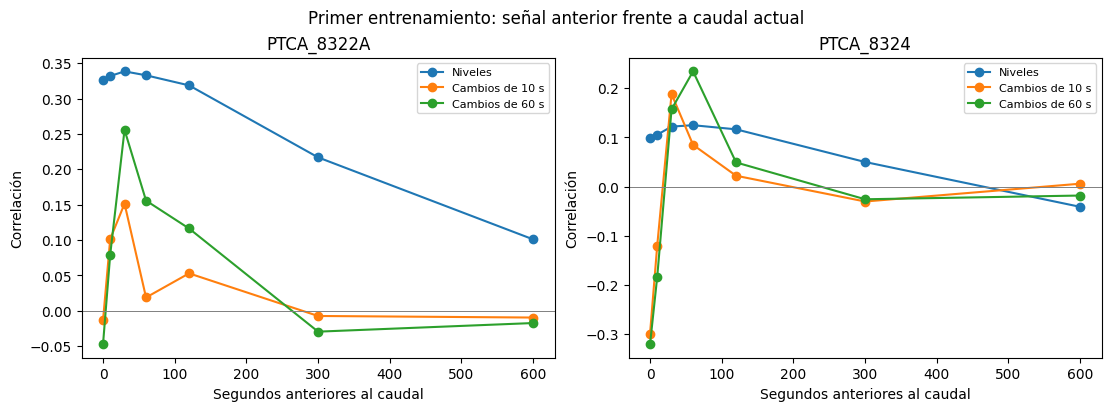

particion,Validación 1,Validación 2,Validación 3
sensor,,,
AIR_8301A.AV_0#,120,30,10
AIR_8301B.AV_0#,120,10,10
FT_8301.AV_0#,10,10,30
FT_8302.AV_0#,600,30,300
FT_8306A.AV_0#,30,30,30
FT_8306B.AV_0#,30,10,10
PTCA_8322A.AV_0#,30,30,30
PTCA_8324.AV_0#,30,30,30
PT_8313A.AV_0#,600,10,10


In [3]:
corr = pd.read_csv(salida / 'correlaciones_entrenamiento.csv')
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, sensor in zip(ejes, PRESIONES):
    for cambio, etiqueta in [(0, 'Niveles'), (10, 'Cambios de 10 s'), (60, 'Cambios de 60 s')]:
        c = corr[(corr.particion == 'Validación 1') & (corr.sensor == sensor) & (corr.cambio_s == cambio)]
        ax.plot(c.rezago_s, c.correlacion, marker='o', label=etiqueta)
    ax.axhline(0, color='grey', lw=.7)
    ax.set(title=sensor.replace('.AV_0#', ''), xlabel='Segundos anteriores al caudal', ylabel='Correlación')
    ax.legend(fontsize=8)
fig.suptitle('Primer entrenamiento: señal anterior frente a caudal actual')
fig.savefig(salida / 'correlaciones_presiones.png', dpi=160)
plt.show()
elegidas = pd.read_csv(salida / 'rezagos_por_entrenamiento.csv')
display(elegidas.pivot(index='sensor', columns='particion', values='rezago_s'))

## Corroboración temporal con el rezago del primer día congelado

Ambas presiones eligen treinta segundos en los tres ajustes crecientes. Esta coincidencia no implica independencia porque los entrenamientos se solapan. A continuación se revisa la relación del candidato inicial en los días siguientes, sin volver a elegirlo con ese día. Muchas otras señales tienen asociaciones débiles o de signo cambiante.

La resolución de los cambios importa: con cambios de sesenta segundos en el primer entrenamiento, PTCA_8324 alcanza su máximo positivo a sesenta segundos. Por eso treinta segundos es una elección de la malla, sin identificar un tiempo físico exacto. PTCA_8324 también tiene una relación contemporánea de cambios negativa más fuerte en valor absoluto que la positiva a treinta segundos.

In [4]:
corroboracion = pd.read_csv(salida / 'corroboracion_rezagos_dia1.csv')
display(corroboracion.pivot(index='sensor', columns='particion', values='correlacion_cambios').round(3))
display(corr[(corr.sensor.isin(PRESIONES)) & (corr.particion == 'Validación 1')]
        .pivot(index=['sensor', 'rezago_s'], columns='cambio_s', values='correlacion').round(4))

particion,Validación 1,Validación 2,Validación 3
sensor,,,
AIR_8301A.AV_0#,-0.006,0.007,-0.006
AIR_8301B.AV_0#,-0.020,-0.007,0.002
FT_8301.AV_0#,0.012,-0.010,0.009
FT_8302.AV_0#,-0.006,-0.004,0.006
FT_8306A.AV_0#,0.020,0.008,-0.014
FT_8306B.AV_0#,-0.010,0.005,0.020
PTCA_8322A.AV_0#,0.150,0.128,0.133
PTCA_8324.AV_0#,0.212,0.175,0.176
PT_8313A.AV_0#,-0.005,-0.016,0.009


cambio_s                       0       10      60
sensor           rezago_s                        
PTCA_8322A.AV_0# 0         0.3261 -0.0135 -0.0471
                 10        0.3319  0.1014  0.0793
                 30        0.3385  0.1515  0.2558
                 60        0.3330  0.0188  0.1558
                 120       0.3187  0.0529  0.1163
                 300       0.2169 -0.0074 -0.0295
                 600       0.1010 -0.0096 -0.0174
PTCA_8324.AV_0#  0         0.0986 -0.2992 -0.3206
                 10        0.1055 -0.1201 -0.1837
                 30        0.1221  0.1884  0.1573
                 60        0.1249  0.0849  0.2345
                 120       0.1165  0.0220  0.0491
                 300       0.0500 -0.0304 -0.0258
                 600      -0.0412  0.0058 -0.0183

## ¿Cuánta mejora aporta la historia de las presiones?

La comparación usa las mismas filas en todos los modelos. La candidata de diecisiete añade dos entradas históricas procedentes de sensores ya presentes; no requiere diecisiete sensores físicos. Las métricas son de validaciones ya usadas, sin test nuevo. Los bloques de una hora son descripciones pareadas, no réplicas independientes para inferencia.

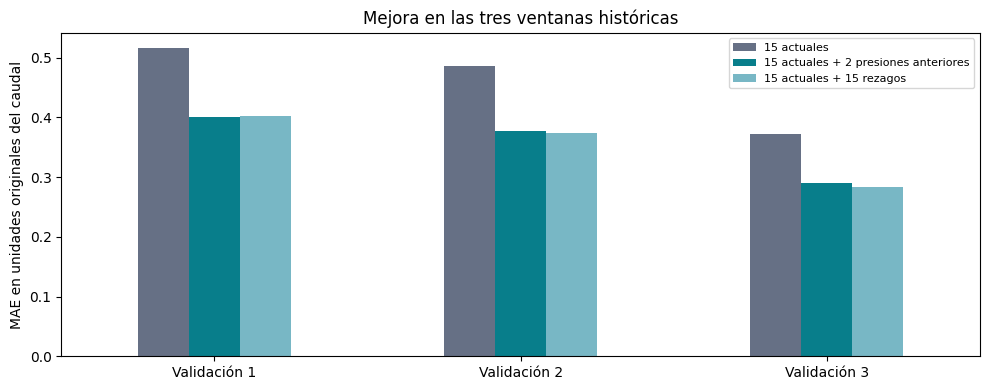

,mejora_15,mejora_29,mejora_dos_presiones
min,-0.001993,-0.004383,-0.007022
mean,0.104930,0.103891,0.101718
max,0.280609,0.267512,0.286384


Horas con menor MAE al añadir las dos presiones: 71 de 72


In [5]:
variantes = ['15 actuales', '15 actuales + historia dos presiones', '15 actuales + rezagos']
diarios = metricas[metricas.variante.isin(variantes)].pivot(index='particion', columns='variante', values='MAE')
ax = diarios[variantes].plot.bar(figsize=(10, 4), rot=0, color=['#667085', '#087e8b', '#78b7c5'])
ax.set(ylabel='MAE en unidades originales del caudal', xlabel='', title='Mejora en las tres ventanas históricas')
ax.legend(['15 actuales', '15 actuales + 2 presiones anteriores', '15 actuales + 15 rezagos'], fontsize=8)
ax.figure.tight_layout()
ax.figure.savefig(salida / 'comparacion_temporal.png', dpi=160)
plt.show()
horas = pd.read_csv(salida / 'errores_por_hora.csv')
display(horas[['mejora_15', 'mejora_29', 'mejora_dos_presiones']].agg(['min', 'mean', 'max']))
print('Horas con menor MAE al añadir las dos presiones:', int((horas.mejora_dos_presiones > 0).sum()), 'de', len(horas))

## Conservación y verificación

El crudo no se modifica. Se guarda cada fila excluida del experimento con sus sensores y motivo; una exclusión de alcance no declara dato incorrecto. Se reproducen aparte las métricas originales sin recorte. Las pruebas independientes revisan el tiempo fuente mediante timestamps, las correlaciones con NumPy y las dieciocho predicciones mediante solución matricial de Ridge. La unidad de dirección temporal verifica que alterar el futuro no cambia la elección en pasado.

In [6]:
import json
control = json.loads((salida / 'verificacion.json').read_text(encoding='utf-8'))
display(pd.Series(control['filas_fuera'], name='filas por motivo; vacío significa elegible'))
print('Crudo:', control['filas_crudo'], '| Elegibles:', control['filas_elegibles'])
print('Artefactos anteriores protegidos:', len(control['huellas_protegidas']))
display(pd.read_csv(salida / 'reproduccion_base_original.csv').round(6))
assert control['dia5_evaluado'] is False and control['promocion_campeona'] is False

segunda_fase_de_muestreo_10s    34560
                                34494
quinto_dia_fuera_del_estudio    17280
sin_historia_comun_de_660s         66
Name: filas por motivo; vacío significa elegible, dtype: int64

Crudo: 86400 | Elegibles: 34494
Artefactos anteriores protegidos: 23


,particion,MAE,RMSE,R2,sesgo,WAPE_pct,error_abs_p95
0,Validación 1,0.515948,0.670095,0.898996,0.008189,0.858947,1.357333
1,Validación 2,0.484420,0.619023,0.956613,0.207154,0.814598,1.230769
2,Validación 3,0.371470,0.469636,0.963036,-0.019737,0.629046,0.923428


## Conclusi?n para el inciso 3 y evaluaci?n gerencial

**Hallazgo:** s? existe historia predictiva ?til. Quince actuales + las dos presiones a treinta segundos reduce MAE de 0.457744 a 0.356026 (22.22 %) y WAPE de 0.768939 % a 0.598068 %. La mejora aparece en los tres d?as. La historia de los otros trece sensores mejora apenas 0.47 % y empeora el primero; no les adjudico retrasos f?sicos firmes.

**Significado y decisi?n:** la trayectoria reciente de las presiones ayuda a distinguir estados con valores actuales similares. La candidata de diecisiete queda a 0.91 % del menor MAE de treinta entradas, dentro de la tolerancia previa de parsimonia. La versi?n de diecisiete es la campeona vigente y debo contrastarla congelada en un periodo nuevo. Impacto observado: menor error hist?rico; sin ahorro econ?mico ni anticipaci?n de falla demostrados.

**Riesgos y certeza:** puede haber din?mica, control, filtrado o asincron?a instrumental. Faltan f?rmula/linaje del caudal compensado y latencias. Correlaci?n no demuestra causalidad ni treinta segundos como tiempo f?sico; certeza moderada hist?rica, baja para interpretaci?n causal/futuro. No certifico funcionamiento al fallar el medidor principal. El estudio responde el requisito de rezagos; la validaci?n externa y confirmaci?n instrumental est?n pendientes.

**Fundamento y uso propuesto:** la presi?n y su trayectoria son indicadores f?sicamente plausibles del almacenamiento de masa/energ?a, demanda y regulaci?n. La utilidad hist?rica justifica conservar esa memoria sin haber identificado su mecanismo exacto. Uso primero Ridge de forma consultiva en paralelo, interpretando discrepancias con el medidor junto con carga y adquisici?n. El respaldo independiente depende del linaje de se?ales; treinta segundos no se convierte en una constante f?sica.

La [interpretaci?n f?sica y decisiones de Serie II](../docs/conclusiones-serie-II.md#interpretaci?n-f?sica-y-decisiones) re?ne evidencia, hip?tesis alternativas y contrastes por inciso.


## Ajuste de la campeona aprobada

Promoción autorizada: quince señales actuales del ajuste final y dos presiones a treinta segundos, usando 34,464 filas de los primeros cuatro días. El quinto día no se evalúa. Los artefactos comparativos previos se preservan y la decisión vigente se guarda en `outputs/campeona_serie2/`.

In [7]:
from scripts.entrenar_campeona_serie2 import entrenar
decision_vigente = entrenar(raiz)
display(pd.Series(decision_vigente))
assert len(decision_vigente['entradas']) == 17
assert decision_vigente['dia5_evaluado_en_promocion'] is False

modelo                                                                    Ridge
variante                        17 entradas: 15 actuales y dos presiones a 30 s
alpha                                                                       100
sensores                      [PT_8313C.AV_0#, PT_8313D.AV_0#, PT_8313F.AV_0...
entradas                      [PT_8313C.AV_0#, PT_8313D.AV_0#, PT_8313F.AV_0...
rezagos_s                       {'PTCA_8322A.AV_0#': 30, 'PTCA_8324.AV_0#': 30}
MAE_validacion                                                         0.356026
WAPE_validacion_pct                                                    0.598068
peor_MAE_validacion                                                    0.400635
validacion_independiente                                                  False
dia5_evaluado_en_promocion                                                False
n_ajuste                                                                  34464
inicio_ajuste                           